<a href="https://colab.research.google.com/github/erifrancelino/ProjetosFaculdade/blob/main/C%C3%B3pia_de_Aula_Pratica_Visualizacao_Dados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Bibliotecas importadas com sucesso!
Banco de dados da ALUCINA criado com sucesso!
Tabela de vendas pronta para receber os registros.
A tabela já possui registros. Nenhum dado foi duplicado.


,id_venda,data_venda,produto,categoria,quantidade,valor_unitario,valor_venda
0,1,2026-10-01,Chaveiro cogumelo,Chaveiros,2,15.0,30.0
1,2,2026-10-02,Marcador de página,Papelaria,3,10.0,30.0
2,3,2026-10-03,Mini xícara,Cerâmica,1,25.0,25.0
3,4,2026-10-05,Chaveiro mini xícara,Chaveiros,2,18.0,36.0
4,5,2026-10-08,Peça autoral personalizada,Cerâmica,1,80.0,80.0
5,6,2026-10-10,Kit artesanal,Kits,1,50.0,50.0


Faturamento total: R$ 251.00
Quantidade de vendas: 6
Unidades vendidas: 10
Ticket médio por venda: R$ 41.83

Faturamento por categoria:


,categoria,faturamento
0,Cerâmica,105.0
1,Chaveiros,66.0
2,Kits,50.0
3,Papelaria,30.0


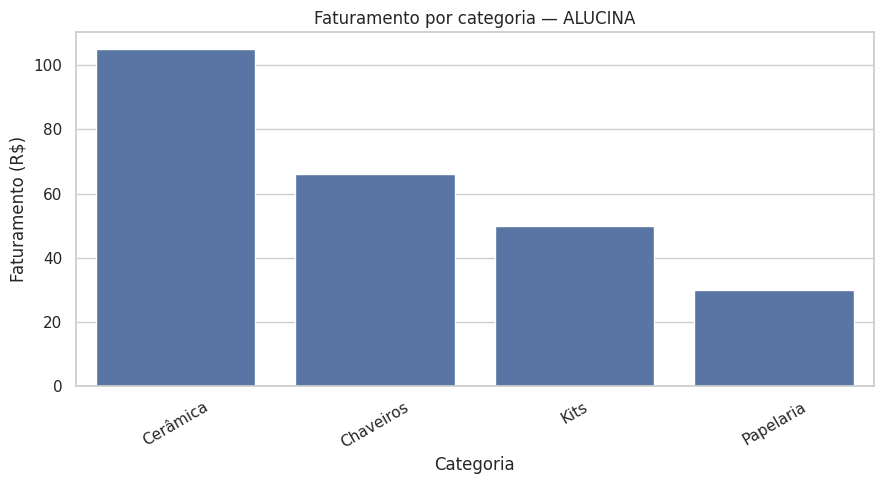

In [ ]:

# Importação das bibliotecas necessárias para a atividade

import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual dos gráficos
sns.set_theme(style="whitegrid")

print("Bibliotecas importadas com sucesso!")


import sqlite3
import pandas as pd

# Conectar ao banco de dados da loja ALUCINA
conexao = sqlite3.connect("banco_alucina.db")
cursor = conexao.cursor()

# Criar a tabela de vendas
cursor.execute("""
CREATE TABLE IF NOT EXISTS vendas1 (
    id_venda INTEGER PRIMARY KEY AUTOINCREMENT,
    data_venda TEXT,
    produto TEXT,
    categoria TEXT,
    quantidade INTEGER,
    valor_unitario REAL,
    valor_venda REAL
)
""")

conexao.commit()

print("Banco de dados da ALUCINA criado com sucesso!")
print("Tabela de vendas pronta para receber os registros.")

# Dados fictícios para testar o banco da ALUCINA
vendas_exemplo = [
    ("2026-10-01", "Chaveiro cogumelo", "Chaveiros", 2, 15.00, 30.00),
    ("2026-10-02", "Marcador de página", "Papelaria", 3, 10.00, 30.00),
    ("2026-10-03", "Mini xícara", "Cerâmica", 1, 25.00, 25.00),
    ("2026-10-05", "Chaveiro mini xícara", "Chaveiros", 2, 18.00, 36.00),
    ("2026-10-08", "Peça autoral personalizada", "Cerâmica", 1, 80.00, 80.00),
    ("2026-10-10", "Kit artesanal", "Kits", 1, 50.00, 50.00),
]

# Inserir os dados somente se a tabela estiver vazia
cursor.execute("SELECT COUNT(*) FROM vendas1")
quantidade_registros = cursor.fetchone()[0]

if quantidade_registros == 0:
    cursor.executemany("""
        INSERT INTO vendas1
        (data_venda, produto, categoria, quantidade, valor_unitario, valor_venda)
        VALUES (?, ?, ?, ?, ?, ?)
    """, vendas_exemplo)

    conexao.commit()
    print("Vendas de exemplo cadastradas!")
else:
    print("A tabela já possui registros. Nenhum dado foi duplicado.")

# Mostrar os dados cadastrados
df_vendas = pd.read_sql_query("SELECT * FROM vendas1", conexao)
display(df_vendas)


# Garantir que a data esteja no formato correto
df_vendas["data_venda"] = pd.to_datetime(df_vendas["data_venda"])

# Calcular indicadores da loja
faturamento_total = df_vendas["valor_venda"].sum()
total_unidades = df_vendas["quantidade"].sum()
numero_vendas = len(df_vendas)
ticket_medio = faturamento_total / numero_vendas if numero_vendas > 0 else 0

print(f"Faturamento total: R$ {faturamento_total:.2f}")
print(f"Quantidade de vendas: {numero_vendas}")
print(f"Unidades vendidas: {total_unidades}")
print(f"Ticket médio por venda: R$ {ticket_medio:.2f}")

print("\nFaturamento por categoria:")
display(
    df_vendas.groupby("categoria")["valor_venda"]
    .sum()
    .sort_values(ascending=False)
    .reset_index(name="faturamento")
)

import matplotlib.pyplot as plt
import seaborn as sns

faturamento_categoria = (
    df_vendas.groupby("categoria", as_index=False)["valor_venda"]
    .sum()
    .sort_values("valor_venda", ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=faturamento_categoria,
    x="categoria",
    y="valor_venda"
)

plt.title("Faturamento por categoria — ALUCINA")
plt.xlabel("Categoria")
plt.ylabel("Faturamento (R$)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

